# Atividade 02 - Introdução a Análise de Dados

- Aluno: Pedro Henrique Barbosa da Cunha
- Curso: Especialização em Engenharia e Análise de Dados
- Turma: 2026-02

In [114]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
print(pd.__version__)
print(np.__version__)

3.1.0
2.5.4


## Carregando os dados

In [115]:
df = pd.read_csv('./precos_carros_brasil.csv')
print(df.shape)
df.head()

(267542, 11)


/var/folders/_9/zswmxgyd4_177wfx8vbhcr6r0000gn/T/ipykernel_14563/4241657778.py:1: DtypeWarning: Columns (1: month_of_reference, 2: fipe_code, 3: authentication, 4: brand, 5: model, 6: fuel, 7: gear, 8: engine_size) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('./precos_carros_brasil.csv')


,year_of_reference,month_of_reference,fipe_code,authentication,brand,model,fuel,gear,engine_size,year_model,avg_price_brl
0,2021.0,January,004001-0,cfzlctzfwrcp,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2002.0,9162.0
1,2021.0,January,004001-0,cdqwxwpw3y2p,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2001.0,8832.0
2,2021.0,January,004001-0,cb1t3xwwj1xp,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Gasoline,manual,1,2000.0,8388.0
3,2021.0,January,004001-0,cb9gct6j65r0,GM - Chevrolet,Corsa Wind 1.0 MPFI / EFI 2p,Alcohol,manual,1,2000.0,8453.0
4,2021.0,January,004003-7,g15wg0gbz1fx,GM - Chevrolet,Corsa Pick-Up GL/ Champ 1.6 MPFI / EFI,Gasoline,manual,"1,6",2001.0,12525.0


## Valores faltantes

In [116]:
# Aqui já consigo ver que tem muitos valores faltando, e algumas colunsa estão com o dtype errado.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 267542 entries, 0 to 267541
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   year_of_reference   202297 non-null  float64
 1   month_of_reference  202297 non-null  str    
 2   fipe_code           202297 non-null  str    
 3   authentication      202297 non-null  str    
 4   brand               202297 non-null  str    
 5   model               202297 non-null  str    
 6   fuel                202297 non-null  str    
 7   gear                202297 non-null  str    
 8   engine_size         202297 non-null  str    
 9   year_model          202297 non-null  float64
 10  avg_price_brl       202297 non-null  float64
dtypes: float64(3), str(8)
memory usage: 22.5 MB


In [117]:
nan_por_linha = df.isna().sum(axis=1)

distribuicao = (
    nan_por_linha.value_counts()
    .sort_index()
    .rename_axis("colunas_nan")
    .reset_index(name="n_registros")
)
distribuicao["pct_registros"] = (distribuicao["n_registros"] / len(df) * 100).round(1)
print(distribuicao)

   colunas_nan  n_registros  pct_registros
0            0       202297           75.6
1           11        65245           24.4


In [118]:
# Validei que cerca de 24% dos registros tem todas as colunas faltando.
# Não há como popular esses dados, então vou dropalos
df = df.dropna(how='all').reset_index(drop=True)
df.isna().sum()

year_of_reference     0
month_of_reference    0
fipe_code             0
authentication        0
brand                 0
model                 0
fuel                  0
gear                  0
engine_size           0
year_model            0
avg_price_brl         0
dtype: int64

## Corrigindo tipos

In [119]:
df['year_of_reference'] = df['year_of_reference'].astype(int)
df['year_model'] = df['year_model'].astype(int)
df['engine_size'] = df['engine_size'].str.replace(',', '.').astype(float)
df.dtypes

year_of_reference       int64
month_of_reference        str
fipe_code                 str
authentication            str
brand                     str
model                     str
fuel                      str
gear                      str
engine_size           float64
year_model              int64
avg_price_brl         float64
dtype: object

## Dados duplicados

In [120]:
duplicados = df[df.duplicated(keep=False)]
print(df.duplicated().sum())
duplicados

2


,year_of_reference,month_of_reference,fipe_code,authentication,brand,model,fuel,gear,engine_size,year_model,avg_price_brl
45791,2021,June,025232-8,5rtdwkpkpq5h,Renault,DUSTER OROCH Dyna. 2.0 Flex 16V Mec.,Gasoline,manual,2.0,2018,69893.0
45793,2021,June,025232-8,5rtdwkpkpq5h,Renault,DUSTER OROCH Dyna. 2.0 Flex 16V Mec.,Gasoline,manual,2.0,2018,69893.0
189895,2022,December,003296-4,3r6c277cnqcb,Ford,Ranger Limited 3.0 PSE 4x4 CD TB Diesel,Diesel,manual,3.0,2007,64638.0
189896,2022,December,003296-4,3r6c277cnqcb,Ford,Ranger Limited 3.0 PSE 4x4 CD TB Diesel,Diesel,manual,3.0,2007,64638.0


In [121]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(202295, 11)


## Estatísticas descritivas

In [122]:
df.describe()

,year_of_reference,engine_size,year_model,avg_price_brl
count,202295.000000,202295.000000,202295.000000,202295.000000
mean,2021.564695,1.822302,2011.271514,52756.765713
std,0.571904,0.734432,6.376241,51628.912116
min,2021.000000,1.000000,2000.000000,6647.000000
25%,2021.000000,1.400000,2006.000000,22855.000000
50%,2022.000000,1.600000,2012.000000,38027.000000
75%,2022.000000,2.000000,2016.000000,64064.000000
max,2023.000000,6.200000,2023.000000,979358.000000


In [123]:
df.describe(exclude='number')

,month_of_reference,fipe_code,authentication,brand,model,fuel,gear
count,202295,202295,202295,202295,202295,202295,202295
unique,12,2091,202295,6,2112,3,2
top,January,001216-5,cfzlctzfwrcp,Fiat,Palio Week. Adv/Adv TRYON 1.8 mpi Flex,Gasoline,manual
freq,24260,425,1,44962,425,168684,161883


## Principais resultados

- Cerca de 24% das linhas eram completamente vazias, essas foram removidas. Também tinha 2 linhas duplicadas que foram removidas.
- Preço: A média é de R$ 52,7 mil e mediana de R$ 38 mil, com máximo de 979 mil.
- Perfil dos carros: são 6 marcas, fiat mais frequente , cerca de 83% são movidos a gasolina e 80% tem câmbio manual (gear)
- Oos modelos dos carros vão de 2000 até 2023.

## Gráficos

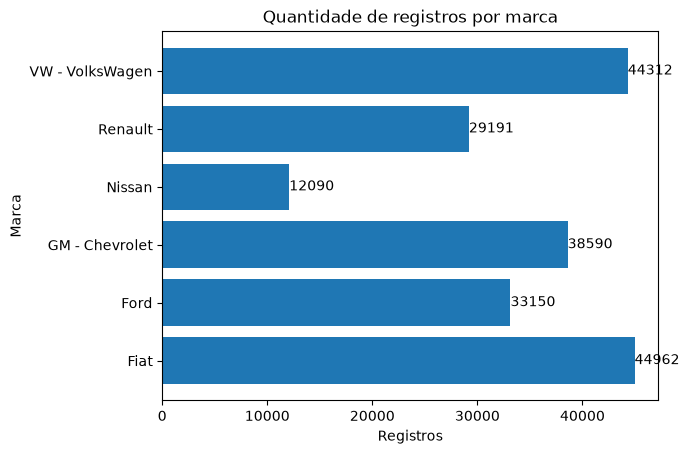

In [124]:
#   distribuição de quantidade de carros por marca

carros_marca = df.groupby('brand').size().reset_index(name='quantidade')

fig, ax = plt.subplots(1, 1)
barras = ax.barh(carros_marca['brand'], carros_marca['quantidade'])
ax.bar_label(barras, labels=carros_marca['quantidade'])
ax.set_title('Quantidade de registros por marca')
ax.set_xlabel('Registros')
ax.set_ylabel('Marca')

plt.show()

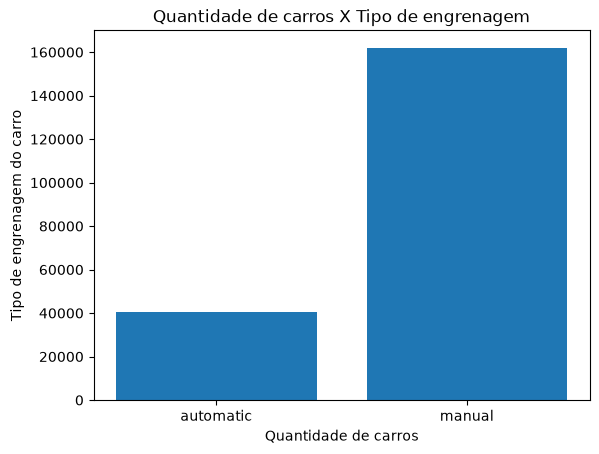

In [125]:
# distribuição da quantidade de carros por tipo de engrenagem do carro
# aqui vemos que tem muito mais carros manual do que automático.

carros_gear = df.groupby('gear').size()

fig, ax = plt.subplots(1, 1)
ax.bar(carros_gear.index, carros_gear)
ax.set_title('Quantidade de carros X Tipo de engrenagem')
ax.set_xlabel('Quantidade de carros')
ax.set_ylabel('Tipo de engrenagem do carro')

plt.show()

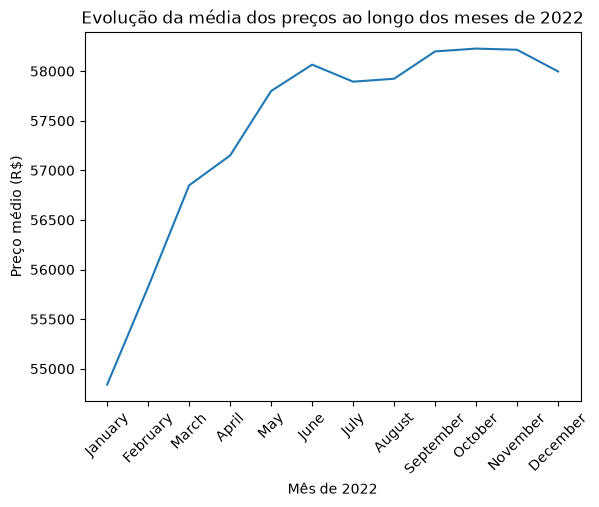

In [126]:
# evolução da média de preço dos carros ao longo dos meses de 2022
preco_tempo = df[df['year_of_reference'] == 2022].groupby(
    'month_of_reference'
)['avg_price_brl'].mean().reset_index(name='avg_price_brl')
preco_tempo['month'] = preco_tempo['month_of_reference'].map({
    'January': 1,
    'February': 2,
    'March': 3,
    'April': 4,
    'May': 5,
    'June': 6,
    'July': 7,
    'August': 8,
    'September': 9,
    'October': 10,
    'November': 11,
    'December': 12
})
preco_tempo = preco_tempo.sort_values('month')

fig, ax = plt.subplots(1, 1)

ax.plot(preco_tempo['month_of_reference'], preco_tempo['avg_price_brl'])
ax.set_title('Evolução da média dos preços ao longo dos meses de 2022')
ax.set_ylabel('Preço médio (R$)')
ax.set_xlabel('Mês de 2022')
plt.xticks(rotation=45)
plt.show()

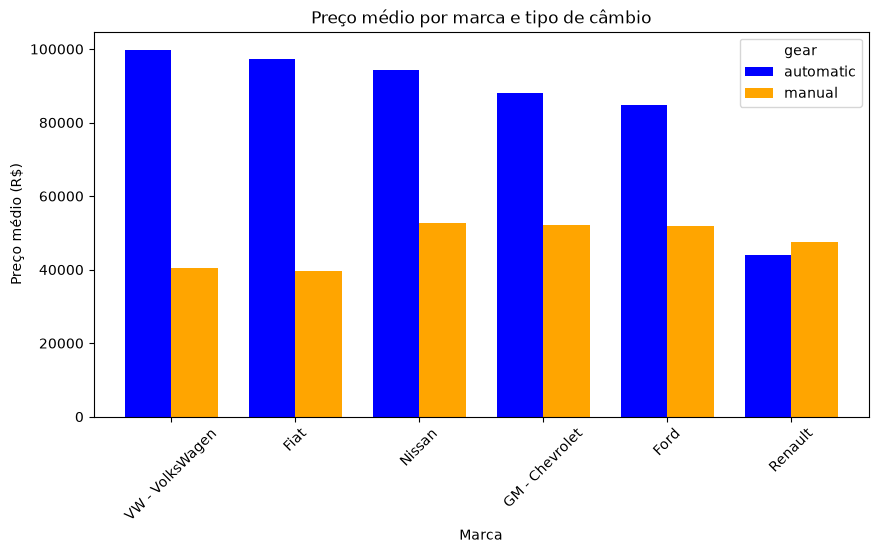

In [127]:
#  distribuição da média de preço dos carros por marca e tipo de engrenagem

preco_marca_gear = df.groupby(['brand', 'gear'])['avg_price_brl'].mean().reset_index(name='avg_price_brl')

tabela = preco_marca_gear.pivot(index='brand', columns='gear', values='avg_price_brl')
tabela = tabela.sort_values('automatic', ascending=False)

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
tabela.plot(
    kind='bar', ax=ax, 
    color=['blue', 'orange'], 
    width=0.75
)
ax.set_xlabel('Marca')
ax.set_ylabel('Preço médio (R$)')
ax.set_title('Preço médio por marca e tipo de câmbio')
plt.xticks(rotation=45)
plt.show()

## Conclusão do gráfico preço médio por marca e tipo de câmbio

- Em 5 marcas (VW, Fiat, Nissan, Chevrolet e Ford) os carros automáticos são aproximadamente o dobro ou mais mais caros
- Isso não é verdade para a Renault, nessa marca os preços dos carros são mais equilibrados, com os manuais sendo ligeiramente mais caros.

Essa conclusão é apenas olhando para o gráfico, acho importante também ver a quantidade de registros por marca, pois com poucos registros não se tem dados confiáveis.

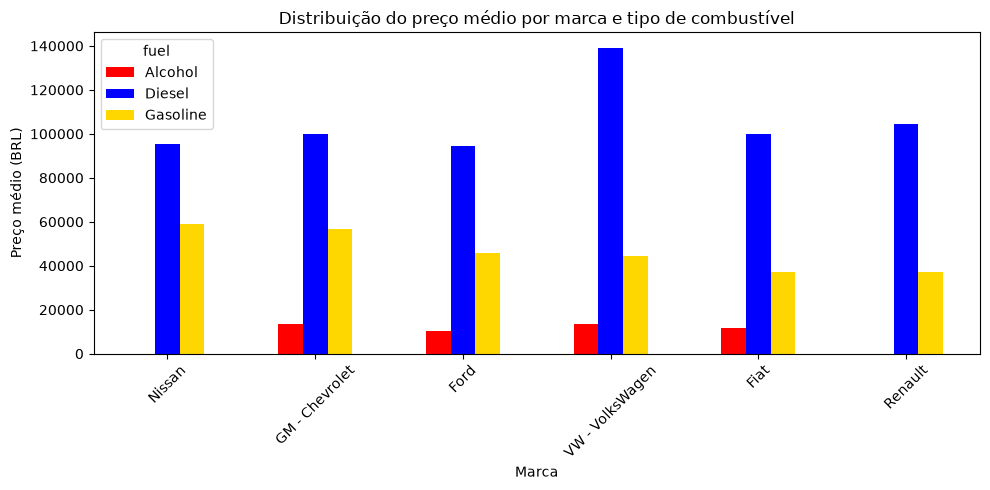

In [128]:
# distribuição da média de preço dos carros por marca e tipo de combustível.

preco_marca_combustivel = df.groupby(['brand', 'fuel'])['avg_price_brl'].mean().reset_index(name='avg_price_brl')
tabela = preco_marca_combustivel.pivot(index='brand', columns='fuel', values='avg_price_brl')
tabela = tabela.sort_values('Gasoline', ascending=False)

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
tabela.plot(
    kind='bar',
    ax=ax,
    color=['red', 'blue', 'gold'],
    width=0.5
)
ax.set_xlabel('Marca')
ax.set_ylabel('Preço médio (BRL)')
ax.set_title('Distribuição do preço médio por marca e tipo de combustível')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Conclusão do gráfico preço médio por marca e tipo de combustível

- Em todas as marcas o preço dos que utilizam Diesel é muito superior ao restante.
- Os mais baratos são os que utilizam alcool.
- Renault e Nissan não possuem registros para alcool.

Essa conclusão é apenas olhando para o gráfico, acho importante também ver a quantidade de registros por marca, pois com poucos registros não se tem dados confiáveis.